# **Loading the Datasets**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/Sample - Superstore.csv',encoding = 'cp1252')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.shape # checking the shape of dataset

(9994, 21)

In [ ]:
df.info() # checking datatypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
df.isnull().sum() # Checking null values

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [ ]:
df.duplicated().sum() # Checking duplicates

np.int64(0)

In [ ]:
df.describe() # Checking statistical values

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [ ]:
df.nunique() # Checking unique values

,0
Row ID,9994
Order ID,5009
Order Date,1237
Ship Date,1334
Ship Mode,4
Customer ID,793
Customer Name,793
Segment,3
Country,1
City,531


# **Cleaning the dataset**

In [ ]:
df_clean = df.copy()

In [ ]:
df_clean.columns.tolist() # Checking Column Names

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [ ]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(' ','_')
)

In [ ]:
df_clean.dtypes

,0
row_id,int64
order_id,object
order_date,object
ship_date,object
ship_mode,object
customer_id,object
customer_name,object
segment,object
country,object
city,object


In [ ]:
df_clean['order_time'] = pd.to_datetime(df_clean['order_date'])
df_clean['ship_date'] = pd.to_datetime(df_clean['ship_date'])

In [ ]:
df_clean[['order_time','ship_date']].dtypes

,0
order_time,datetime64[ns]
ship_date,datetime64[ns]


In [ ]:
df_clean

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,region,product_id,category,sub-category,product_name,sales,quantity,discount,profit,order_time
0,1,CA-2016-152156,11/8/2016,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016-11-08
1,2,CA-2016-152156,11/8/2016,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016-11-08
2,3,CA-2016-138688,6/12/2016,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016-06-12
3,4,US-2015-108966,10/11/2015,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015-10-11
4,5,US-2015-108966,10/11/2015,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015-10-11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,1/21/2014,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028,2014-01-21
9990,9991,CA-2017-121258,2/26/2017,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332,2017-02-26
9991,9992,CA-2017-121258,2/26/2017,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932,2017-02-26
9992,9993,CA-2017-121258,2/26/2017,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200,2017-02-26


In [ ]:
df_clean['category'].value_counts()

,count
category,
Office Supplies,6026
Furniture,2121
Technology,1847


In [ ]:
df_clean['region'].value_counts()

,count
region,
West,3203
East,2848
Central,2323
South,1620


In [ ]:
df_clean['segment'].value_counts()

,count
segment,
Consumer,5191
Corporate,3020
Home Office,1783


In [ ]:
df_clean.select_dtypes(include = 'object').columns

Index(['order_id', 'order_date', 'ship_mode', 'customer_id', 'customer_name',
       'segment', 'country', 'city', 'state', 'region', 'product_id',
       'category', 'sub-category', 'product_name'],
      dtype='object')

In [ ]:
for col in df_clean.select_dtypes(include = 'object').columns:
  df_clean[col] = df_clean[col].str.strip()

In [ ]:
total_sales = df_clean['sales'].sum()
total_profit = df_clean['profit'].sum()
total_orders = df_clean['order_id'].nunique()
total_customers = df_clean['customer_id'].nunique()

print('Total Sales',total_sales)
print('Total Profit', total_profit)
print('Total Orders',total_orders)
print('Total Customers',total_customers)

Total Sales 2297200.8603
Total Profit 286397.0217
Total Orders 5009
Total Customers 793


In [ ]:
profit_margin = (total_profit/total_sales) * 100
print('Profit Margin',round(profit_margin,2), '%')

Profit Margin 12.47 %


In [ ]:
average_order_value = total_sales/total_orders
print('Average Order Value', round(average_order_value,2))

Average Order Value 458.61


In [ ]:
#grouping sales by category
category_sales = (
    df_clean.groupby('category')['sales']
    .sum()
    .sort_values(ascending = False)
)

category_sales

,sales
category,
Technology,836154.0330
Furniture,741999.7953
Office Supplies,719047.0320


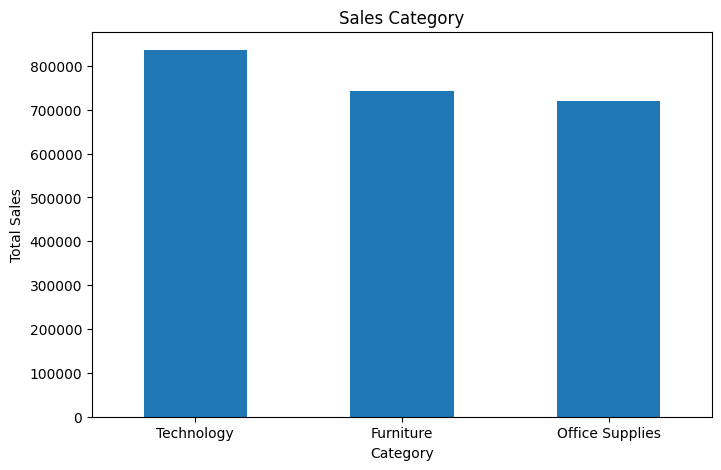

In [ ]:
#visualizing
category_sales.plot(kind = 'bar',figsize = (8,5))

plt.title('Sales Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation = 0)
plt.show()


In [ ]:
#category profit
category_profit = (
    df_clean.groupby('category')['profit']
    .sum()
    .sort_values(ascending = False)
)

category_profit

,profit
category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


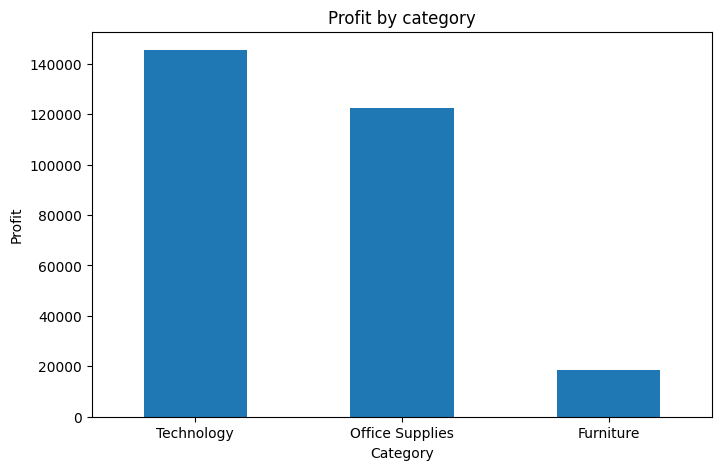

In [ ]:
category_profit.plot(kind = 'bar',figsize = (8,5))

plt.title('Profit by category')
plt.xlabel('Category')
plt.ylabel('Profit')
plt.xticks(rotation = 0)
plt.show()

In [ ]:
region_sales = (
    df_clean.groupby('region')['sales']
    .sum()
    .sort_values(ascending = False)
)

region_sales

,sales
region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


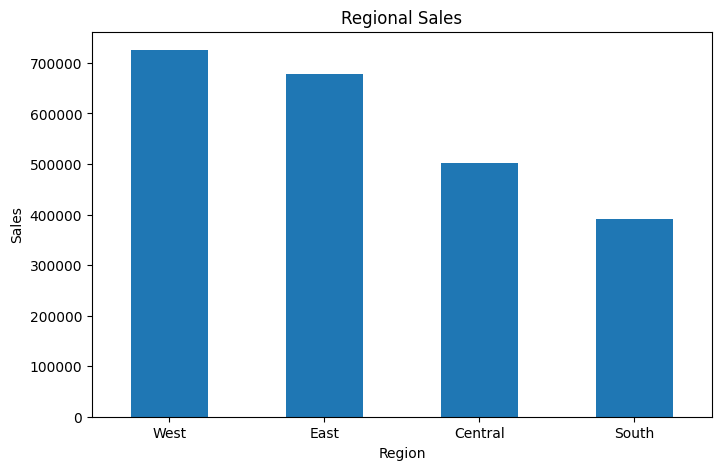

In [ ]:
region_sales.plot(kind = 'bar',figsize = (8,5))

plt.title('Regional Sales')
plt.xlabel('Region')
plt.ylabel('Sales')
plt.xticks(rotation = 0)
plt.show()

In [ ]:
#regional profit
region_profit = (
    df_clean.groupby('region')['profit']
    .sum()
    .sort_values(ascending = False)
)
region_profit

,profit
region,
West,108418.4489
East,91522.7800
South,46749.4303
Central,39706.3625


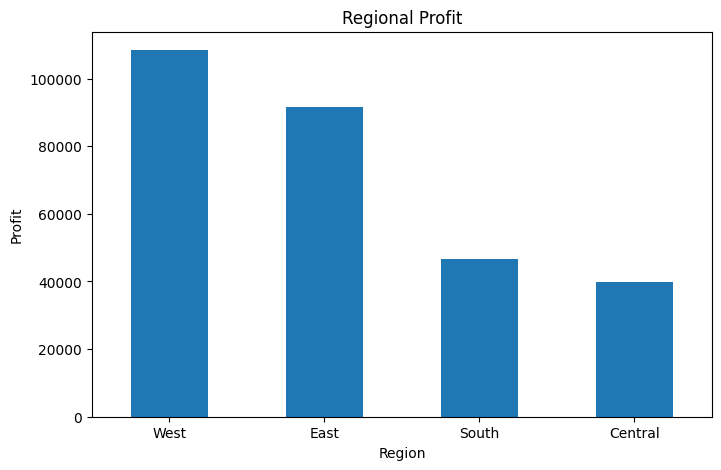

In [ ]:
region_profit.plot(kind = 'bar',figsize = (8,5))

plt.title('Regional Profit')
plt.xlabel('Region')
plt.ylabel('Profit')
plt.xticks(rotation = 0)
plt.show()

In [ ]:
print(df_clean['order_date'].dtype)
print(df_clean['order_date'].head(10))
print(df_clean['order_date'].min())
print(df_clean['order_date'].max())


object
0     11/8/2016
1     11/8/2016
2     6/12/2016
3    10/11/2015
4    10/11/2015
5      6/9/2014
6      6/9/2014
7      6/9/2014
8      6/9/2014
9      6/9/2014
Name: order_date, dtype: object
1/1/2017
9/9/2017


In [ ]:
df_clean['order_date'] = pd.to_datetime(
    df_clean['order_date'],
    errors='coerce'
)

In [ ]:
print(df_clean['order_date'].dtype)

datetime64[ns]


In [ ]:
month_sales = (
    df_clean.groupby(df_clean['order_date'].dt.strftime('%Y-%m'))['sales']
    .sum()
    .sort_index()
)

month_sales

,sales
order_date,
2014-01,14236.8950
2014-02,4519.8920
2014-03,55691.0090
2014-04,28295.3450
2014-05,23648.2870
2014-06,34595.1276
2014-07,33946.3930
2014-08,27909.4685
2014-09,81777.3508


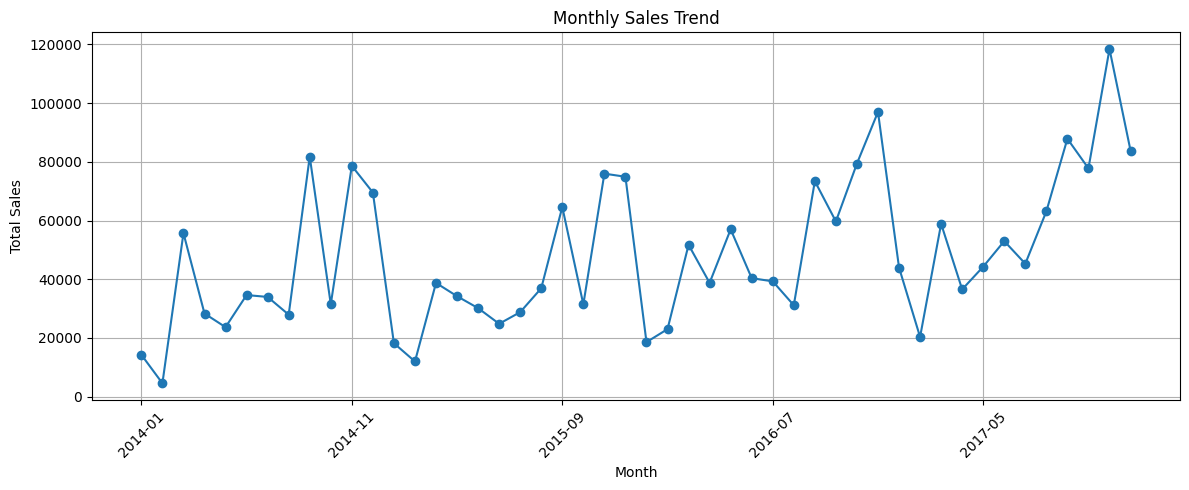

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

month_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
product_sales = (
    df_clean.groupby('product_name')['sales']
    .sum()
    .sort_values(ascending = False)
)

top_10_products = product_sales.head(10)
top_10_products

,sales
product_name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


/tmp/ipykernel_1620/3835400688.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


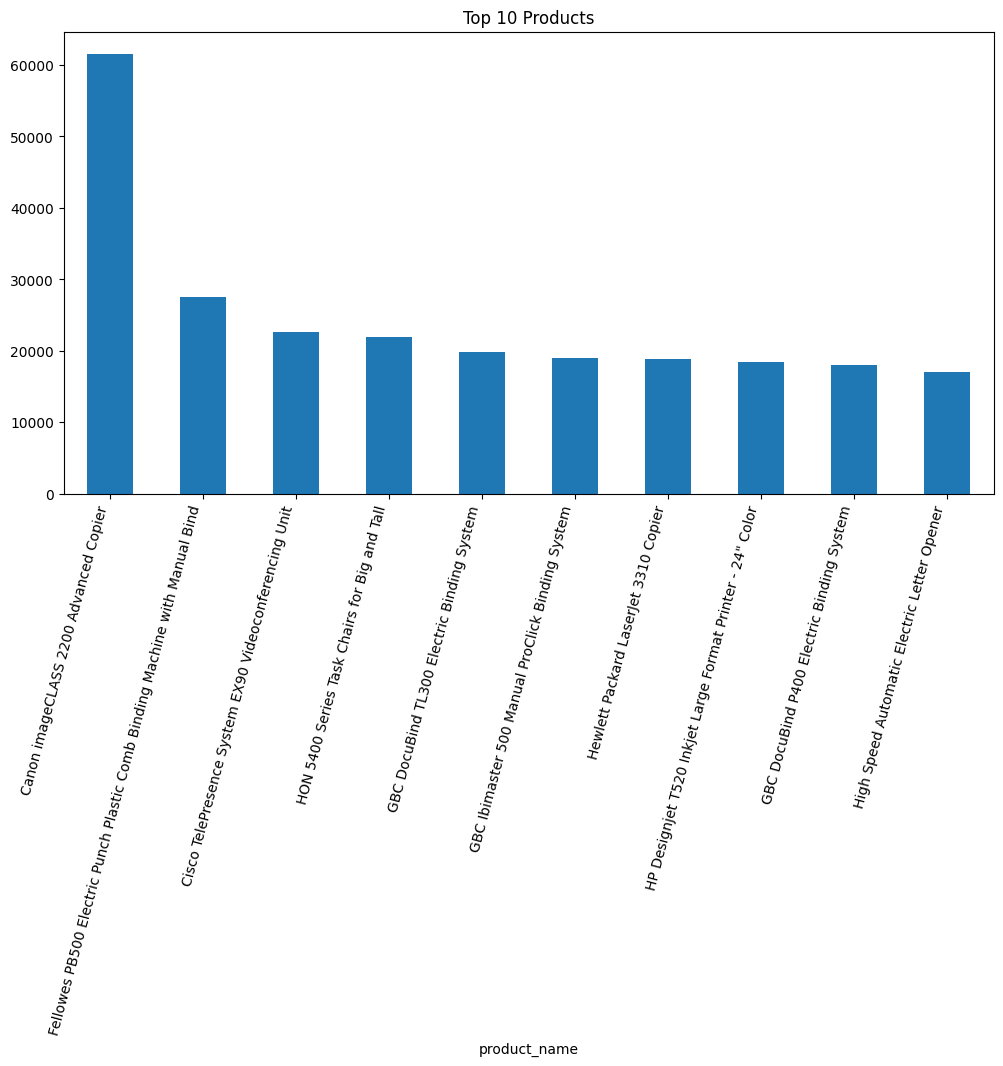

In [ ]:
plt.figure(figsize = (12,6))

top_10_products.plot(kind = 'bar')

plt.title('Top 10 Products')
plt.xticks(rotation = 75,ha = 'right')
plt.tight_layout()
plt.show()

In [ ]:
segment_sales = (
    df_clean.groupby('segment')['sales']
    .sum()
    .sort_values(ascending = False)
)
segment_sales

,sales
segment,
Consumer,1.161401e+06
Corporate,7.061464e+05
Home Office,4.296531e+05


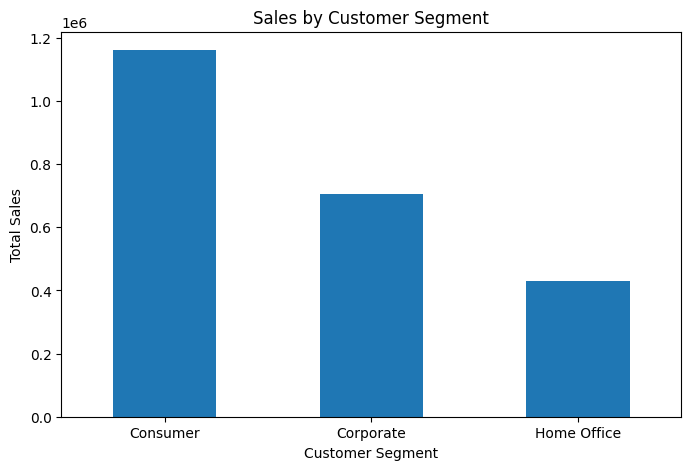

In [ ]:
segment_sales.plot(kind = 'bar',figsize = (8,5))

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation = 0)
plt.show()

In [ ]:
segment_profit = (
    df_clean.groupby('segment')['profit']
    .sum()
    .sort_values(ascending = False)
)

segment_profit

,profit
segment,
Consumer,134119.2092
Corporate,91979.1340
Home Office,60298.6785


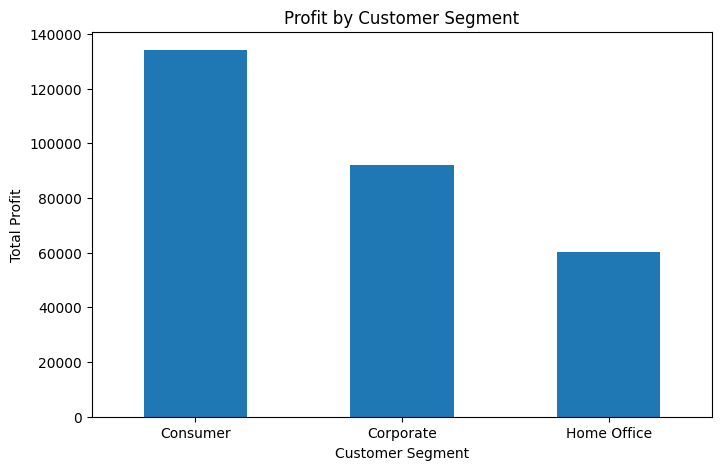

In [ ]:
segment_profit.plot(kind = 'bar', figsize = (8,5))

plt.title('Profit by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Profit')
plt.xticks(rotation = 0)
plt.show()

In [ ]:
#analyse discount
discount_analysis = (
    df_clean.groupby('discount')
    .agg(
        total_sales = ('sales','sum'),
        total_profit = ('profit','sum'),
        total_quantity = ('quantity','sum')
    )
    .sort_index()
)

discount_analysis

,total_sales,total_profit,total_quantity
discount,,,
0.00,1.087908e+06,320987.6032,18267
0.10,5.436935e+04,9029.1770,373
0.15,2.755852e+04,1418.9915,198
0.20,7.645944e+05,90337.3060,13660
0.30,1.032267e+05,-10369.2774,849
0.32,1.449346e+04,-2391.1377,105
0.40,1.164178e+05,-23057.0504,786
0.45,5.484974e+03,-2493.1111,45
0.50,5.891854e+04,-20506.4281,241


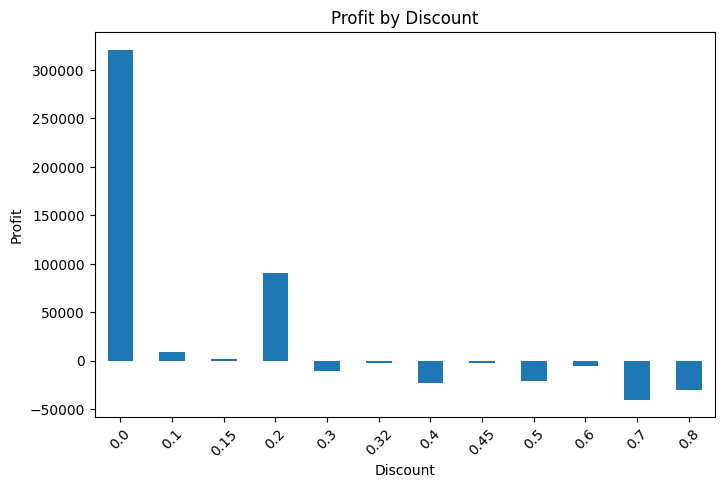

In [ ]:
plt.figure(figsize = (8,5))

discount_analysis['total_profit'].plot(kind = 'bar')
plt.title('Profit by Discount')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.xticks(rotation = 45)
plt.show()

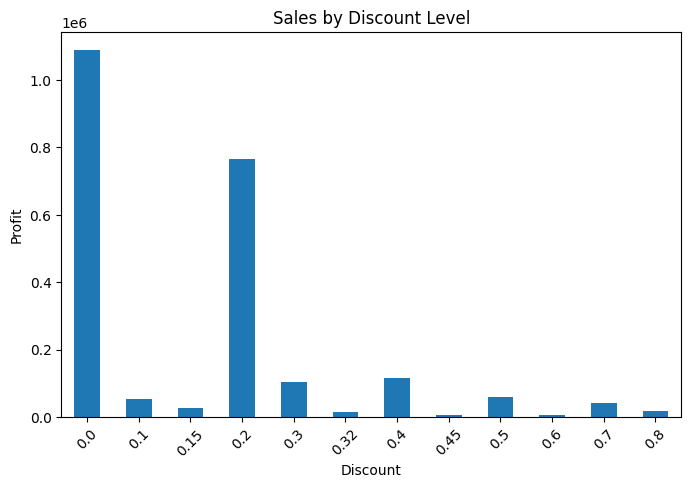

In [ ]:
plt.figure(figsize = (8,5))

discount_analysis['total_sales'].plot(kind = 'bar')
plt.title('Sales by Discount Level')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.xticks(rotation = 45)
plt.show()

In [ ]:
region_analysis = (
    df_clean.groupby('region')
    .agg(
        total_sales = ('sales','sum'),
        total_profit = ('profit','sum'),
        total_quantity = ('quantity','sum')
    )
    .sort_values('total_sales',ascending = False)
)
region_analysis

,total_sales,total_profit,total_quantity
region,,,
West,725457.8245,108418.4489,12266
East,678781.2400,91522.7800,10618
Central,501239.8908,39706.3625,8780
South,391721.9050,46749.4303,6209


In [ ]:
df_clean.rename(columns={'sub-category': 'sub_category'}, inplace=True)

In [ ]:
df_clean = df_clean.drop(columns=['order_time'])

df_clean.to_csv('superstore_cleaned.csv', index=False)

print(df_clean.columns.tolist())
print("Total columns:", len(df_clean.columns))

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit']
Total columns: 21
